# TVA plant scheduling: starter notebook

Every day TVA decides which power plants to switch on for each hour of tomorrow, so supply covers demand plus a safety margin (the **reserve**). This is called **unit commitment**. The on/off choices are the hard yes-or-no part. Once they are made, setting each plant's output (**economic dispatch**) is easy classical math, and `check.py` does it for you.

| Section | Milestone | What you do |
|---|---|---|
| 1 | 1 | Load 5 plants and 24 hours of demand. Schedule 6 hours by hand. |
| 2 | 2 | Classical baseline: an exact MILP (provided) and a cheapest-first rule (**TODO 1**). |
| 3 | 3 | Write one hour as a QUBO (**TODO 2**, **TODO 3**) and check it by brute force. |
| 4 | 4 | Solve one hour with QAOA on a simulator. |
| 5 and 6 | 4 and 6 | Run QAOA hour by hour for the whole day. Compare with the baseline. |
| 7 | 5 | Run one hour on IonQ hardware through qBraid. |

Run the cells from top to bottom. A cell marked **TODO** stops with `NotImplementedError` until you fill it in. Everything else already works.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 1. The plants and the demand

Each row of `data/plants.csv` is one plant, built from a real unit in the RTS-GMLC test grid (see `data/README.md`).

| Column | Meaning |
|---|---|
| `pmin_mw`, `pmax_mw` | When on, the plant makes between pmin and pmax MW |
| `marginal_cost_per_mwh` | Fuel cost of each extra MWh |
| `no_load_cost_per_h` | Cost per hour of just being on |
| `startup_cost` | Paid each time the plant switches on |
| `min_up_h`, `min_down_h` | Once on, it stays on this many hours. Once off, it stays off this many hours. |
| `on_at_start` | 1 if the plant is already running at midnight |

One hour of a plant that is on costs: no-load cost + marginal cost × output, plus the startup cost if it just switched on.

plant     type                              pmin  pmax   $/MWh  no-load $/h  startup $  min up  min down
COAL      coal steam                         140   350   21.69          546     36,750     24h       48h
GAS_CC    gas combined cycle                 168   350   26.84          206     27,650      8h        5h
PEAKER_A  gas combustion turbine              20    50   28.89          443      5,150      3h        3h
PEAKER_B  gas combustion turbine (older)      20    50   39.51          749      5,150      3h        3h
OIL       oil combustion turbine              20    50  101.02          694        130      1h        1h


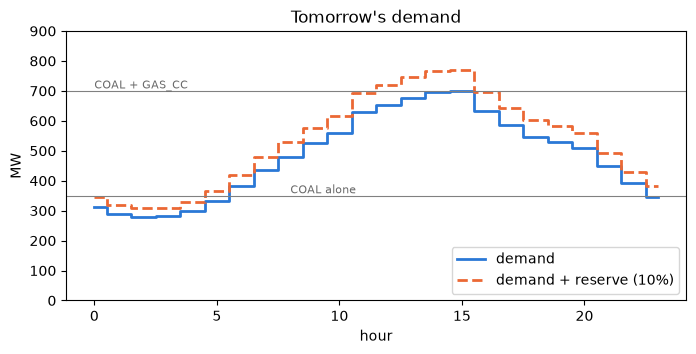

In [2]:
print(f"{'plant':<10}{'type':<32}{'pmin':>6}{'pmax':>6}{'$/MWh':>8}{'no-load $/h':>13}"
      f"{'startup $':>11}{'min up':>8}{'min down':>10}")
for p in plants:
    print(f"{p['plant_id']:<10}{p['type']:<32}{p['pmin_mw']:>6.0f}{p['pmax_mw']:>6.0f}"
          f"{p['marginal_cost_per_mwh']:>8.2f}{p['no_load_cost_per_h']:>13,.0f}"
          f"{p['startup_cost']:>11,.0f}{p['min_up_h']:>7.0f}h{p['min_down_h']:>9.0f}h")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(hours, demand, where="mid", color=COLORS["milp"], lw=2, label="demand")
ax.step(hours, demand + reserve, where="mid", color=COLORS["qaoa"], lw=2, ls="--",
        label="demand + reserve (10%)")
for level, text, x in [(350, "COAL alone", 8), (700, "COAL + GAS_CC", 0)]:
    ax.axhline(level, color="gray", lw=0.8)
    ax.text(x, level + 8, text, color="dimgray", fontsize=8)
ax.set(xlabel="hour", ylabel="MW", title="Tomorrow's demand", ylim=(0, 900))
ax.legend(loc="lower right")
plt.show()

### Milestone 1: schedule 6 hours by hand

Edit `my_schedule`: one row per hour (hours 0 to 5), one column per plant, 1 = on. The checker prints the cost and any rules broken. How close you are to the best possible is yours to find out in Milestone 2. A spreadsheet works too.

In [27]:
#               COAL  GAS_CC  PEAKER_A  PEAKER_B  OIL
my_schedule = [[1,    0,      0,        0,        0],   # hour 0
               [1,    0,      0,        0,        0],   # hour 1
               [1,    0,      0,        0,        0],   # hour 2
               [1,    0,      0,        0,        0],   # hour 3
               [1,    0,      0,        0,        0],   # hour 4
               [1,    0,      0,        0,        0]]   # hour 5

hand_result = check_schedule(plants, demand[:6], reserve[:6], my_schedule)

Total cost: $42,144  (startups $0, no-load $3,276, energy $38,868)
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
     5  -          reserve not met  capacity 350 MW < demand + reserve 364 MW


## 2. Classical baseline (Milestone 2)

**MILP** (mixed-integer linear program): the standard classical tool for unit commitment. The costs and rules are written as linear equations over on/off variables and outputs, and a solver (HiGHS, inside scipy) finds the provably cheapest schedule. Ours is `solve_milp` in `check.py`, about 60 lines. Read it once.

MILP solved in 0.049 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


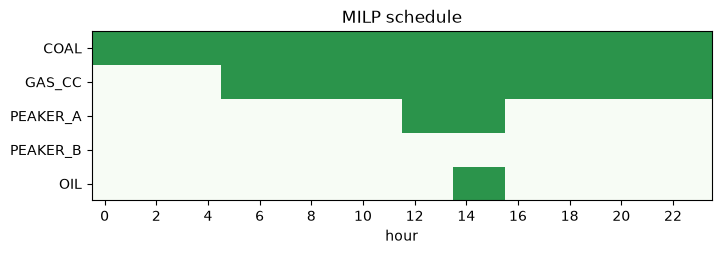

In [28]:
milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

### TODO 1: the cheapest-first rule

A rule a person might use: rank plants by cost per MWh at full output, then each hour switch plants on down the list until capacity covers demand + reserve.

- Cost per MWh at full output = `marginal_cost_per_mwh + no_load_cost_per_h / pmax_mw`.
- `np.argsort(values)` gives plant indices from cheapest to most expensive.
- For each hour `t`, add plants in that order until the sum of their `pmax_mw` is at least `demand[t] + reserve[t]`.

The rule ignores startup costs and min up/down times. Look at what that costs, and which rules it breaks.

Total cost: $330,594  (startups $37,950, no-load $20,288, energy $272,356)
MILP optimum: $327,924   gap: +0.81%
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
    16  PEAKER_B   min up broken    turned off after 2 h on (needs 3)


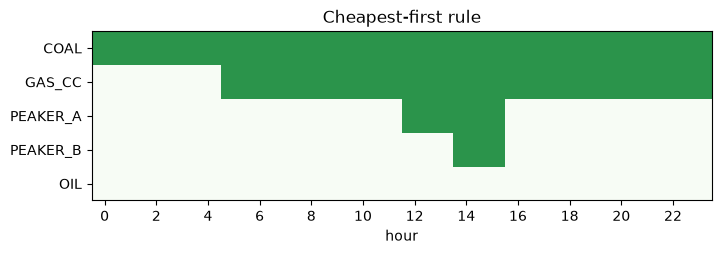

In [5]:
def cheapest_first(plants, demand, reserve):
    # Returns a (hours x plants) array of 0/1.
    schedule = np.zeros((len(demand), len(plants)), dtype=int)
    # TODO 1: rank the plants, then fill each hour (see the hints above).
    full_cost = np.array([p["marginal_cost_per_mwh"] + p["no_load_cost_per_h"] / p["pmax_mw"]
                          for p in plants])
    order = np.argsort(full_cost)                     # cheapest plant index first
    pmax = np.array([p["pmax_mw"] for p in plants])
    for t in range(len(demand)):
        need = demand[t] + reserve[t]
        capacity = 0.0
        for i in order:                               # switch plants on down the list...
            if capacity >= need:                      # ...until capacity covers demand + reserve
                break
            schedule[t, i] = 1
            capacity += pmax[i]
    return schedule


rule_schedule = cheapest_first(plants, demand, reserve)
rule_result = check_schedule(plants, demand, reserve, rule_schedule, milp_cost=milp_cost)
plot_schedule(rule_schedule, "Cheapest-first rule")
plt.show()

## 3. One hour as a QUBO (Milestone 3)

*First: one teammate works through `qaoa_primer.ipynb` (the 6-node part, about 45 minutes), ideally while others do milestones 1 and 2. Bring back one sentence on how its Max-Cut cost relates to the QUBO below.*

**QUBO** (quadratic unconstrained binary optimization): a cost function over 0/1 variables that has only single terms and pair terms. The QAOA code in this notebook takes the problem in this form.

One hour uses 8 qubits:

| Qubits | Meaning |
|---|---|
| 0 to 4 | $x_i = 1$ if plant $i$ is on (COAL, GAS_CC, PEAKER_A, PEAKER_B, OIL) |
| 5 to 7 | helper (slack) bits $s_0, s_1, s_2$ for the safety-margin rule |

QAOA should find the bits with the lowest energy

$$E = \sum_i c_i x_i + A \Big(\sum_i a_i x_i - (s_0 + 2 s_1 + 4 s_2) - r\Big)^2$$

- $c_i$ is the cost of having plant $i$ on this hour (TODO 2).
- The rule is "capacity of the plants that are on ≥ demand + reserve". We count capacity in 50 MW blocks: plant $i$ is $a_i = \text{pmax}_i / 50$ blocks (COAL and GAS_CC are 7, the small plants are 1), and the hour needs $r = \lceil (\text{demand} + \text{reserve}) / 50 \rceil$ blocks.
- A QUBO cannot say "≥". So the slack bits spell out the spare blocks in binary: spare $= s_0 + 2 s_1 + 4 s_2$, from 0 to 7. If the plants have enough capacity, with at most 7 spare blocks, one slack setting makes the bracket exactly 0 and the penalty vanishes. If they are short, no slack setting helps and the penalty is at least $A$.
- Three slack bits cover 0 to 7 spare blocks (up to 350 MW). That is enough for the best choice in every hour of this day. Two things this QUBO doesn't get right: a choice with more than 7 spare blocks is penalized even though it's allowed, and the rule "minimum outputs can't exceed demand" isn't in the QUBO at all. Find an hour and a choice for each. Which step in section 5 catches them?
- $A$ is the penalty weight. It must be bigger than what any plant saves by breaking the rule. We start with $A = 2 \max_i c_i$.

### TODO 2: the cost of one plant for one hour

$$c_i = \text{startup}_i \cdot (1 - \text{was\_on}_i) + \text{no\_load}_i + \text{pmin}_i \cdot (\text{marginal}_i - \text{marginal}_\text{cheapest})$$

Why: a plant that is on must make at least pmin MW. The rest of the demand comes from the cheapest plant with room to spare (COAL, whenever it has room), whichever plants you pick. So what plant $i$ adds is its startup (only if it was off last hour), its no-load cost, and its extra price on those pmin MW.

This is an approximation. It ignores who makes the last MW when COAL is already full. The checker uses the exact cost, so you can measure how often this picks the true best. Try a few demand levels and previous on/off states. (Improving it is a stretch goal.)

`was_on[i]` is 1 if plant `i` was on in the previous hour. `marginal_cheapest` is the smallest `marginal_cost_per_mwh` in the fleet.

In [10]:
def plant_hour_costs(plants, was_on):
    # c[i] = approximate cost in $ of having plant i on for this hour.
    c = np.zeros(len(plants))
    # TODO 2: fill c[i] with the formula above.
    marginal_cheapest = min(p["marginal_cost_per_mwh"] for p in plants)
    for i, p in enumerate(plants):
        startup = p["startup_cost"] * (1 - was_on[i])          # only paid if it was off last hour
        no_load = p["no_load_cost_per_h"]                      # paid every hour it's on
        extra = p["pmin_mw"] * (p["marginal_cost_per_mwh"] - marginal_cheapest)  # forced pmin MW, priced vs cheapest
        c[i] = startup + no_load + extra
    return c

### TODO 3: the QUBO matrix

Store the QUBO as an 8 × 8 matrix `Q` and a number `offset`:

$$\text{energy}(y) = \sum_j Q[j, j]\, y_j + \sum_{j<k} Q[j, k]\, y_j y_k + \text{offset}$$

The diagonal holds single terms, the upper triangle holds pair terms, the lower triangle is unused.

Hint: put all 8 bits in one list $y = (x_0, \dots, x_4, s_0, s_1, s_2)$ with weights $b = (a_0, \dots, a_4, -1, -2, -4)$. The bracket is then $\sum_j b_j y_j - r$. Because $y_j^2 = y_j$ for 0/1 bits,

$$\Big(\sum_j b_j y_j - r\Big)^2 = \sum_j (b_j^2 - 2 r b_j)\, y_j + \sum_{j<k} 2 b_j b_k\, y_j y_k + r^2$$

1. Cost part: add `c[i]` to `Q[i, i]` for each plant.
2. Penalty part: multiply each term of the expansion by `A` and add it to the right place: single terms on the diagonal, pair terms at `Q[j, k]` with `j < k`, the constant to `offset`.

`b` and `r` are computed for you.

In [11]:
BLOCK_MW = 50               # capacity is counted in 50 MW blocks
N_SLACK = 3                 # slack bits: spare capacity = s0 + 2*s1 + 4*s2 blocks
N_QUBITS = N + N_SLACK      # qubits 0..4 = plants, 5..7 = slack


def build_qubo(plants, demand_mw, reserve_mw, was_on, penalty=None):
    # QUBO for one hour. Returns (Q, offset).
    c = plant_hour_costs(plants, was_on)
    A = 2 * c.max() if penalty is None else penalty
    b = np.array([p["pmax_mw"] / BLOCK_MW for p in plants] + [-(2 ** k) for k in range(N_SLACK)])
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)       # blocks needed this hour
    Q = np.zeros((N_QUBITS, N_QUBITS))
    offset = 0.0
    # TODO 3: add the cost part and the penalty part to Q and offset.
# 1) Cost part: each plant's hourly cost sits on its own diagonal entry.
    for i in range(N):
        Q[i, i] += c[i]
    # 2) Penalty part: A * (sum_j b_j y_j - r)^2, expanded using y_j^2 = y_j.
    for j in range(N_QUBITS):
        Q[j, j] += A * (b[j] ** 2 - 2 * r * b[j])          # single terms-> diagonal
        for k in range(j + 1, N_QUBITS):
            Q[j, k] += A * 2 * b[j] * b[k]                  # pair terms -> upper triangle
    offset += A * r ** 2
    return Q, offset

In [26]:
# Bit j of an integer index = qubit j. Row k of INDEX_BITS holds the 8 bits of index k.
# (Qiskit prints bitstrings with qubit 0 as the LAST character. Using integer indices
#  everywhere means you never have to reverse a string.)
INDEX_BITS = (np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1
PLANT_INDEX = INDEX_BITS[:, :N] @ (2 ** np.arange(N))   # on/off choice (0..31) inside each index


def all_energies(Q, offset):
    # QUBO energy of all 256 bitstrings.
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", INDEX_BITS, U, INDEX_BITS) + offset


def brute_force_qubo(Q, offset):
    E = all_energies(Q, offset)
    k = int(np.argmin(E))
    return INDEX_BITS[k], E[k]


def label(choice):
    # Plant names for an on/off choice given as a 0..31 index or a list of 0/1.
    on = [(choice >> i) & 1 for i in range(N)] if np.isscalar(choice) else choice
    return "+".join(n for n, u in zip(names, on) if u) or "none"

### Check your QUBO

The brute force tries all 256 bitstrings of your QUBO and keeps the cheapest. `check_hour` compares its plant bits with the best of all 32 on/off choices, using the exact cost. **Milestone 3 is done when it prints "Match!"** That checks one hour, given the hour before; it doesn't prove a good full day.

Compare the best choice for this hour with what the MILP picked for it. If they differ, which one is right, and why?

In [13]:
TEST_HOUR = 12
was_on = milp_schedule[TEST_HOUR - 1]        # who was on the hour before (from the MILP)
Q, offset = build_qubo(plants, demand[TEST_HOUR], reserve[TEST_HOUR], was_on)
bits, energy = brute_force_qubo(Q, offset)
print(f"Cheapest QUBO bitstring: plants {bits[:N]}, slack {bits[N:]}, energy {energy:,.0f}")
check_hour(plants, demand[TEST_HOUR], reserve[TEST_HOUR], bits[:N], was_on=was_on)
print("(The MILP picked", label(list(milp_schedule[TEST_HOUR])), "for this hour.)")

Cheapest QUBO bitstring: plants [1 1 0 0 1], slack [0 0 0], energy 4,028
Your choice: COAL+GAS_CC+OIL  ->  valid, cost $18,810
Match!
(The MILP picked COAL+GAS_CC+PEAKER_A for this hour.)


In [25]:
# Every hour at once, with the MILP's previous hour as "who was on".
start_state = [int(p["on_at_start"]) for p in plants]
matches = 0
for t in hours:
    was = milp_schedule[t - 1] if t > 0 else start_state
    Qt, off_t = build_qubo(plants, demand[t], reserve[t], was)
    bits_t, _ = brute_force_qubo(Qt, off_t)
    matches += check_hour(plants, demand[t], reserve[t], bits_t[:N], was_on=was, verbose=False)["matches_best"]
print(f"Your QUBO's cheapest answer matches the brute-force best in {matches} of {len(hours)} hours.")

Your QUBO's cheapest answer matches the brute-force best in 24 of 24 hours.


## 4. QAOA for one hour

These helpers are provided:

1. `qubo_to_ising` replaces each bit $y$ with $(1 - z)/2$, which gives single-qubit $Z$ terms and $ZZ$ pair terms.
2. `qaoa_circuit` builds `p` layers: an `rz` on each qubit and an `rzz` on each pair (the cost layer), then an `rx` on each qubit (the mixer).
3. `run_qaoa` tunes the angles with COBYLA, using the exact statevector (fast for 8 qubits). It minimizes the average energy, rescaled to the range 0 to 1.
4. `choice_probs` adds up the probability over the slack qubits, giving the chance of each of the 32 on/off choices.

Be clear about this in your story: to tune the angles, `run_qaoa` scores all 256 bitstrings first, which already finds the best one, and the loop below checks all 32 choices for its report. Count that classical work in your timing.

In [24]:
def qubo_to_ising(Q):
    # y = (1 - z) / 2 turns the QUBO into  sum_j h_j Z_j + sum_jk J_jk Z_j Z_k + constant.
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4
                h[j] -= Q[j, k] / 4
                h[k] -= Q[j, k] / 4
    return h, J


def qaoa_circuit(Q, p=1):
    # Parameterized QAOA circuit with p layers. Returns (circuit, parameters).
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))   # keeps angles in a sane range
    gammas, betas = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(len(Q))
    qc.h(range(len(Q)))
    for layer in range(p):
        for j, hj in enumerate(h):
            if hj != 0:
                qc.rz(2 * gammas[layer] * hj / scale, j)
        for (j, k), Jjk in J.items():
            qc.rzz(2 * gammas[layer] * Jjk / scale, j, k)
        qc.rx(2 * betas[layer], range(len(Q)))
    return qc, list(gammas) + list(betas)


def run_qaoa(Q, offset, p=1, start=None, maxiter=60):
    # Tune the angles on the exact statevector. Returns (angles, probabilities of all 256 bitstrings).
    E = all_energies(Q, offset)
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = qaoa_circuit(Q, p)

    def probs_at(angles):
        return Statevector(qc.assign_parameters(dict(zip(params, angles)))).probabilities()

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:     # coarse grid for one (gamma, beta), used in every layer
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, 1.5, 8)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


def choice_probs(probs):
    # Probability of each on/off choice (0..31), summed over the slack qubits.
    return np.bincount(PLANT_INDEX, weights=probs, minlength=2 ** N)

QAOA for hour 12: 0.42 s, angles [ 0.638 -0.655]


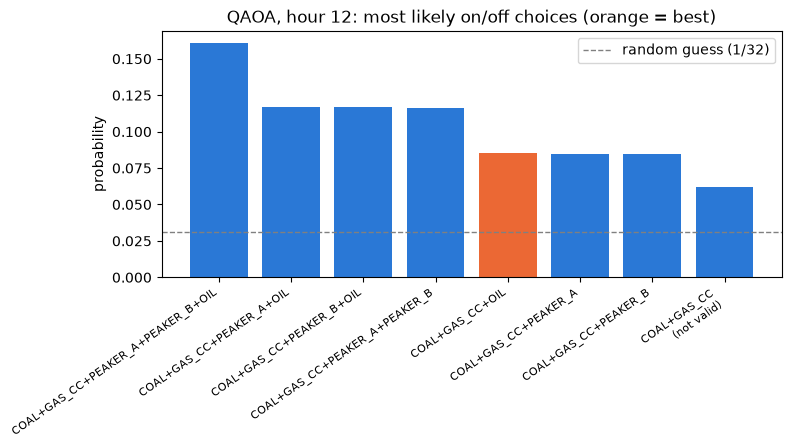

P(best choice) = 0.085   random guess = 0.031


In [16]:
start = time.perf_counter()
angles, probs = run_qaoa(Q, offset, p=1)
print(f"QAOA for hour {TEST_HOUR}: {time.perf_counter() - start:.2f} s, angles {np.round(angles, 3)}")

pc = choice_probs(probs)
best_k = int(bits[:N] @ (2 ** np.arange(N)))          # brute-force best from above
top = np.argsort(-pc)[:8]
valid = [hour_ok(plants, demand[TEST_HOUR], reserve[TEST_HOUR], [(k >> i) & 1 for i in range(N)]) for k in top]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(top)), pc[top], color=[COLORS["qaoa"] if k == best_k else COLORS["milp"] for k in top])
ax.axhline(1 / 2 ** N, color="gray", ls="--", lw=1, label="random guess (1/32)")
ax.set_xticks(range(len(top)), [label(int(k)) + ("" if ok else "\n(not valid)") for k, ok in zip(top, valid)],
              rotation=35, ha="right", fontsize=8)
ax.set(ylabel="probability", title=f"QAOA, hour {TEST_HOUR}: most likely on/off choices (orange = best)")
ax.legend()
plt.show()
print(f"P(best choice) = {pc[best_k]:.3f}   random guess = {1 / 2 ** N:.3f}")

## 5. The whole day, hour by hour (Milestone 4)

`schedule_day` goes through the 24 hours in order. For each hour it:

1. Asks `check.locks` which plants min up / min down times force on or off (classical).
2. Builds your QUBO, plus a penalty for breaking those locks.
3. Runs QAOA, starting from the previous hour's angles (warm start).
4. Draws `shots` samples, like a quantum computer would.
5. Keeps the cheapest sampled on/off choice that passes the classical check (`hour_ok`, exact `hour_cost`).
6. Carries that choice forward as "who was on" for the next hour.

If no sample passes, it keeps a choice that breaks a lock (or, failing that, the most common sample), and the checker lists the broken rule.

In [23]:
def add_locks(Q, offset, must_on, must_off, weight):
    # Penalty weight*(1 - x_i) for a plant that must stay on, weight*x_i for one that must stay off.
    Q = Q.copy()
    for i in must_on:
        Q[i, i] -= weight
        offset += weight
    for i in must_off:
        Q[i, i] += weight
    return Q, offset


def schedule_day(p=1, shots=200, sampler="qaoa", seed=7, penalty=None):
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], None
    was_on = [int(x["on_at_start"]) for x in plants]
    for t in hours:
        must_on, must_off = locks(plants, history)
        Q, offset = build_qubo(plants, demand[t], reserve[t], was_on, penalty=penalty)
        Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
        if sampler == "qaoa":
            angles, probs = run_qaoa(Q, offset, p=p, start=angles)
        else:                                   # random guessing, for comparison
            probs = np.full(2 ** N_QUBITS, 1 / 2 ** N_QUBITS)
        samples = rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())
        seen = [list(INDEX_BITS[k][:N]) for k in np.unique(PLANT_INDEX[samples])]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:                              # nothing fully valid: allow breaking a lock
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        if ok:
            pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
        else:                                   # still nothing: take the most common sample
            pick = list(INDEX_BITS[np.bincount(PLANT_INDEX[samples]).argmax()][:N])
        ref = check_hour(plants, demand[t], reserve[t], pick, was_on, must_on, must_off, verbose=False)
        best_k = None if ref["best_choice"] is None else int(np.dot(ref["best_choice"], 2 ** np.arange(N)))
        valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], INDEX_BITS[k][:N], must_on, must_off)
                               for k in samples])
        log.append(dict(hour=t, pick=pick, matches_best=ref["matches_best"], valid_share=valid_share,
                        p_best=0.0 if best_k is None else choice_probs(probs)[best_k],
                        Q=Q, offset=offset, angles=angles))
        history.append(pick)
        was_on = pick
    return np.array(history), log

In [18]:
start = time.perf_counter()
qaoa_schedule, qaoa_log = schedule_day(p=1, shots=200)
print(f"QAOA for 24 hours: {time.perf_counter() - start:.1f} s\n")
qaoa_result = check_schedule(plants, demand, reserve, qaoa_schedule, milp_cost=milp_cost)

print(f"\n{'hour':>4}  {'choice':<28}{'best for this hour?':>20}{'P(best)':>9}{'valid samples':>15}")
for row in qaoa_log:
    print(f"{row['hour']:>4}  {label(row['pick']):<28}{'yes' if row['matches_best'] else 'no':>20}"
          f"{row['p_best']:>9.3f}{row['valid_share']:>14.0%}")

QAOA for 24 hours: 2.7 s

Total cost: $351,082  (startups $43,360, no-load $26,163, energy $281,559)
MILP optimum: $327,924   gap: +7.06%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

hour  choice                       best for this hour?  P(best)  valid samples
   0  COAL                                         yes    0.049           70%
   1  COAL                                         yes    0.049           70%
   2  COAL                                         yes    0.049           70%
   3  COAL                                         yes    0.049           66%
   4  COAL                                         yes    0.049           66%
   5  COAL+OIL                                     yes    0.042           60%
   6  COAL+PEAKER_A+OIL                            yes    0.034           46%
   7  COAL+PEAKER_A+PEAKER_B+OIL                   yes    0.048           30%
   8  COAL+GAS_CC+PEAKER_A+PEAKER_B                 yes    0.070           15%
   9

## 6. Results vs the baseline

As an honesty check, the same loop also runs with random guesses instead of QAOA. Compare them: if random guessing does as well, what is making your schedule good? Look at every step of the loop, not just the sampler, before you answer.

**Required for milestone 4:** run QAOA and random guessing at 5, 10, 20, 50 and 200 shots, with at least 5 seeds each (`schedule_day(shots=..., sampler=..., seed=...)`). Make a table: how many days come out valid, and the cost gap of the valid ones. Explain it before you tune anything.

Then try:
- More layers (`p=2`), more optimizer steps, or a smaller penalty weight (`schedule_day(penalty=...)`; the default is 2 × the biggest plant cost).
- Why does the hour-by-hour schedule cost more than the MILP?

method                          daily cost $       gap  rules broken
MILP (optimal)                       327,924    +0.00%             0
cheapest-first rule                  330,594    +0.81%             1
QAOA, hour by hour                   351,082    +7.06%             0
random guesses, hour by hour         351,082    +7.06%             0


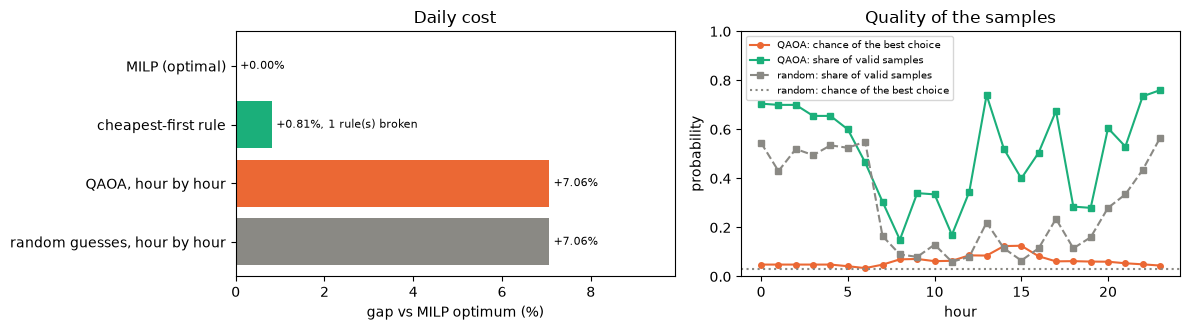

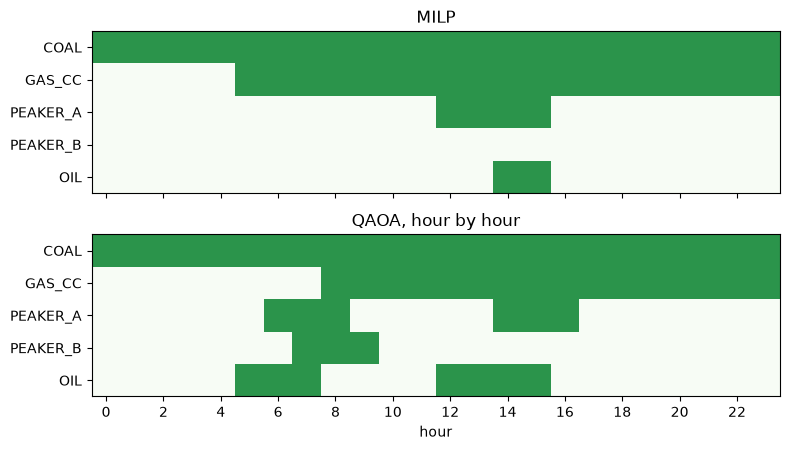

In [19]:
random_schedule, random_log = schedule_day(sampler="random")
random_result = check_schedule(plants, demand, reserve, random_schedule, milp_cost=milp_cost, verbose=False)

results = {"MILP (optimal)": (milp_result, COLORS["milp"]),
           "cheapest-first rule": (rule_result, COLORS["rule"]),
           "QAOA, hour by hour": (qaoa_result, COLORS["qaoa"]),
           "random guesses, hour by hour": (random_result, COLORS["random"])}
print(f"{'method':<30}{'daily cost $':>14}{'gap':>10}{'rules broken':>14}")
for name, (r, _) in results.items():
    print(f"{name:<30}{r['total_cost']:>14,.0f}{r['gap_pct']:>+9.2f}%{len(r['violations']):>14}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].barh(list(results), [r["gap_pct"] for r, _ in results.values()],
             color=[color for _, color in results.values()])
for y, (r, _) in enumerate(results.values()):
    broken = f", {len(r['violations'])} rule(s) broken" if r["violations"] else ""
    axes[0].text(max(r["gap_pct"], 0) + 0.1, y, f"{r['gap_pct']:+.2f}%{broken}", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.4 * max(max(r["gap_pct"] for r, _ in results.values()), 1))
axes[0].set(xlabel="gap vs MILP optimum (%)", title="Daily cost")
axes[1].plot(hours, [row["p_best"] for row in qaoa_log], "o-", color=COLORS["qaoa"], ms=4,
             label="QAOA: chance of the best choice")
axes[1].plot(hours, [row["valid_share"] for row in qaoa_log], "s-", color=COLORS["rule"], ms=4,
             label="QAOA: share of valid samples")
axes[1].plot(hours, [row["valid_share"] for row in random_log], "s--", color=COLORS["random"], ms=4,
             label="random: share of valid samples")
axes[1].axhline(1 / 2 ** N, color=COLORS["random"], ls=":", label="random: chance of the best choice")
axes[1].set(xlabel="hour", ylabel="probability", ylim=(0, 1), title="Quality of the samples")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
plot_schedule(milp_schedule, "MILP", ax=axes[0]).set_xlabel("")
plot_schedule(qaoa_schedule, "QAOA, hour by hour", ax=axes[1])
plt.tight_layout()
plt.show()

## 7. One hour on IonQ hardware (Milestone 5)

1. Pick an hour. We reuse the QUBO the loop built for it (locks included) and tune a 1-layer circuit.
2. Check the size. IonQ advises keeping hardware circuits to a few dozen two-qubit gates, so use `p=1`. Check the count the next cell prints. On IonQ each pair interaction becomes one native two-qubit (ZZ) gate, so the count there is lower than the CX count. How noisy do you expect the hardware result to be, and why?
3. Run on IonQ's free simulator with its noise model first. When that works, switch to the QPU. Real runs use credits, at most 200 shots, and queues can take hours, so send it early. If the queue is stuck, keep your job ID and your noisy-simulator result to show the judges, and ask a qBraid mentor about IQM Garnet. Recommended, and free: run it on Quantinuum's H2 emulator too (the cell has the lines). Before you switch devices, save the result you have (for example `counts_ionq_sim = counts`) so you can chart both.

In [20]:
HW_HOUR = 14                 # near the peak (hour 15 is the peak); try others
entry = qaoa_log[HW_HOUR]
hw_angles, hw_probs = run_qaoa(entry["Q"], entry["offset"], p=1, start=entry["angles"])
circuit, params = qaoa_circuit(entry["Q"], p=1)
qc = QuantumCircuit(N_QUBITS, N_QUBITS)
qc.compose(circuit.assign_parameters(dict(zip(params, hw_angles))), inplace=True)
qc.measure(range(N_QUBITS), range(N_QUBITS))

cx = transpile(qc, basis_gates=["rz", "sx", "x", "cx"]).count_ops().get("cx", 0)
print(f"Hour {HW_HOUR}: {qc.num_qubits} qubits, {cx} CX gates after transpiling")

sim = AerSimulator()
sim_counts = sim.run(transpile(qc, sim), shots=200, seed_simulator=11).result().get_counts()

Hour 14: 8 qubits, 56 CX gates after transpiling


In [21]:
# --- Run on a quantum computer through qBraid ---
from qbraid.runtime import QbraidProvider
import warnings
warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway

provider = QbraidProvider()   # in qBraid Lab this uses your account automatically

# 1) Practice for free: IonQ's simulator with a realistic noise model
device = provider.get_device("ionq:ionq:sim:simulator")
job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})

# 2) Your real hardware run (uses credits). Swap in the QPU when you're ready:
# device = provider.get_device("ionq:ionq:qpu:forte-1")    # or "aws:ionq:qpu:forte-1" if this one shows as unavailable
# job = device.run(qc, shots=200)

# 3) Also free: Quantinuum's H2 emulator. It models a real trapped-ion computer's noise, readout
#    error included. Accept Quantinuum's terms once first (Devices > Quantinuum in your qBraid account).
#    It's an emulator: label its results that way, not as hardware.
# device = provider.get_device("quantinuum:quantinuum:sim:h2-emulator")
# job = device.run(qc, shots=200)

print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record
counts = job.result().data.get_counts()
print("Most common results:", dict(sorted(counts.items(), key=lambda kv: -kv[1])[:5]))

Device: ionq:ionq:sim:simulator | Job ID: ionq:ionq:sim:simulator-e165-qjob-6af81350e50ba2cb1a452313
Most common results: {'00011111': 10, '00110111': 10, '00001111': 7, '00101111': 7, '00001011': 6}


simulator (ideal)                        valid shots   56%   best choice 11.5%
ionq:ionq:sim:simulator                  valid shots   47%   best choice 11.0%


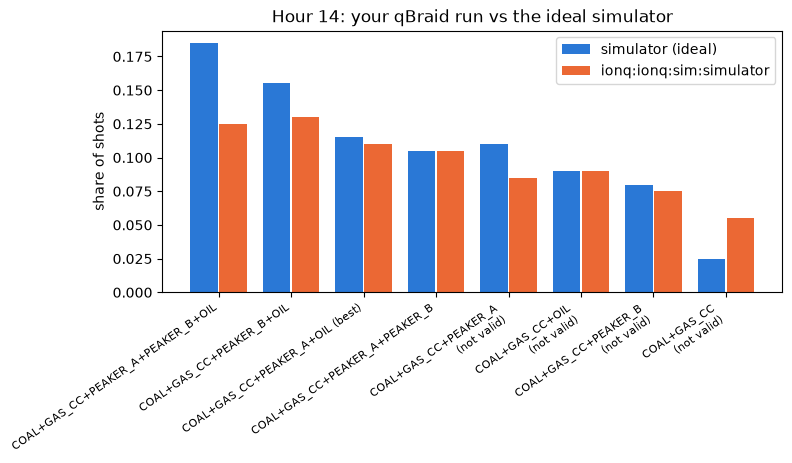

In [22]:
def choice_shares(counts):
    # Share of shots for each on/off choice. int(key, 2) reads Qiskit's bitstring
    # (qubit 0 is the last character) as an index, so bit j = qubit j.
    total = sum(counts.values())
    share = np.zeros(2 ** N)
    for key, c in counts.items():
        share[int(key.replace(" ", ""), 2) & (2 ** N - 1)] += c / total   # low 5 bits = plants
    return share


must_on, must_off = locks(plants, list(qaoa_schedule[:HW_HOUR]))
hw = check_hour(plants, demand[HW_HOUR], reserve[HW_HOUR], qaoa_schedule[HW_HOUR],
                was_on=qaoa_schedule[HW_HOUR - 1], must_on=must_on, must_off=must_off, verbose=False)
if hw["best_choice"] is None:
    raise ValueError(f"No valid on/off choice at hour {HW_HOUR}; pick another HW_HOUR")
best_k = int(np.dot(hw["best_choice"], 2 ** np.arange(N)))
is_valid = np.array([hour_ok(plants, demand[HW_HOUR], reserve[HW_HOUR], [(k >> i) & 1 for i in range(N)],
                             must_on, must_off) for k in range(2 ** N)])
sim_share, ionq_share = choice_shares(sim_counts), choice_shares(counts)
for name, share in [("simulator (ideal)", sim_share), (device.id, ionq_share)]:
    print(f"{name:<40} valid shots {share[is_valid].sum():5.0%}   best choice {share[best_k]:5.1%}")

top = np.argsort(-(sim_share + ionq_share))[:8]
x = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(x - 0.2, sim_share[top], 0.38, color=COLORS["milp"], label="simulator (ideal)")
ax.bar(x + 0.2, ionq_share[top], 0.38, color=COLORS["qaoa"], label=device.id)
ax.set_xticks(x, [label(int(k)) + (" (best)" if k == best_k else "") + ("" if is_valid[k] else "\n(not valid)")
                  for k in top], rotation=35, ha="right", fontsize=8)
ax.set(ylabel="share of shots", title=f"Hour {HW_HOUR}: your qBraid run vs the ideal simulator")
ax.legend()
plt.show()

## What to have ready for the judges

| Milestone | Be ready to show |
|---|---|
| 1 | Your 6-hour hand schedule and its cost |
| 2 | The MILP's optimal daily cost, and the cheapest-first rule's gap and broken rules |
| 3 | The "Match!" output for at least one hour (one hour, given the hour before), how many of the 24 hours match, and one sentence on how the primer's Max-Cut cost relates to yours |
| 4 | Your QAOA-vs-random table across shots and seeds, your hour-by-hour daily cost, its gap to the MILP, and any rules broken |
| 5 | Your run record (device, job ID, shots, status), the CX count, and the chart, labeled simulator, emulator or QPU |
| 6 | Your five slides (see the main README): who schedules the plants and what they use today, the cost gap and how often answers were valid, total time (including the hardware queue), a sourced value scenario, and what you learned. Rehearse in the time the organizers give you |

Understanding and clarity count more than code. This notebook is a starter: add your own cells, notebooks and tools, and expand as far as you like. If something failed or you couldn't find a solution, say so clearly and explain why.

Due Sunday 9:00 AM: your pitch deck and your code as a ZIP. See "What to submit" in the main README for where.